# Part 1 — Decision Trees on the Cryotherapy Dataset

Tuning a `DecisionTreeClassifier` on a small clinical dataset (90 patients) that records whether cryotherapy successfully removed warts, based on patient and treatment attributes. Covers depth tuning, feature importance, and reading the tree structure itself.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score

## Loading the Data

In [2]:
df = pd.read_excel('Cryotherapy.xlsx') 

df = pd.get_dummies(df, columns=['Type'], drop_first=True, dtype=int)

X = df.drop(columns=['Result_of_Treatment'])
y = df['Result_of_Treatment']

## Splitting the Dataset

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

## Scaling

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train data shape: {X_train_scaled.shape}")
print(f"Test data shape: {X_test_scaled.shape}")

Train data shape: (72, 7)
Test data shape: (18, 7)


## Tuning `max_depth` over [2, 4, 6, 8, None]

In [9]:
max_depths = [2, 4, 6, 8, None]
results_dt = []

best_f1 = -1
best_depth = None
best_dt_model = None

for depth in max_depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_scaled, y_train)

    # 1. Predict on training dataset & calculate Train Accuracy
    y_train_pred = dt.predict(X_train_scaled)
    train_acc = accuracy_score(y_train, y_train_pred)

    # 2. Predict on test dataset & calculate Test metrics
    y_test_pred = dt.predict(X_test_scaled)
    test_acc = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    # 3. Append all results to the list
    results_dt.append({
        'max_depth': depth, 
        'Train Accuracy': train_acc, 
        'Test Accuracy': test_acc, 
        'Test F1-Score': test_f1
    })
    
    # Finding best max_depth using Test F1-Score
    if test_f1 > best_f1:
        best_f1 = test_f1
        best_depth = depth
        best_dt_model = dt 


# Convert results to DataFrame
dt_results_df = pd.DataFrame(results_dt)
print("Decision Tree Results for different max_depths:")
print(dt_results_df.to_string(index=False))
print("-" * 30)
print(f"Best max_depth based on F1-Score is: {best_depth} (F1-Score: {best_f1:.4f})")

Decision Tree Results for different max_depths:
 max_depth  Train Accuracy  Test Accuracy  Test F1-Score
       2.0        0.888889       0.833333       0.833849
       4.0        0.972222       0.666667       0.658009
       6.0        1.000000       0.777778       0.777778
       8.0        1.000000       0.777778       0.777778
       NaN        1.000000       0.777778       0.777778
------------------------------
Best max_depth based on F1-Score is: 2 (F1-Score: 0.8338)


## Feature Importance

In [ ]:
best_dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_dt.fit(X_train_scaled, y_train)

# Predict on both splits
y_train_pred = best_dt.predict(X_train_scaled)
y_test_pred = best_dt.predict(X_test_scaled)

# Calculate Accuracies
dt_train_accuracy = accuracy_score(y_train, y_train_pred)
dt_test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Decision Tree Training Accuracy: {dt_train_accuracy * 100:.2f}%")
print(f"Decision Tree Testing Accuracy: {dt_test_accuracy * 100:.2f}%")


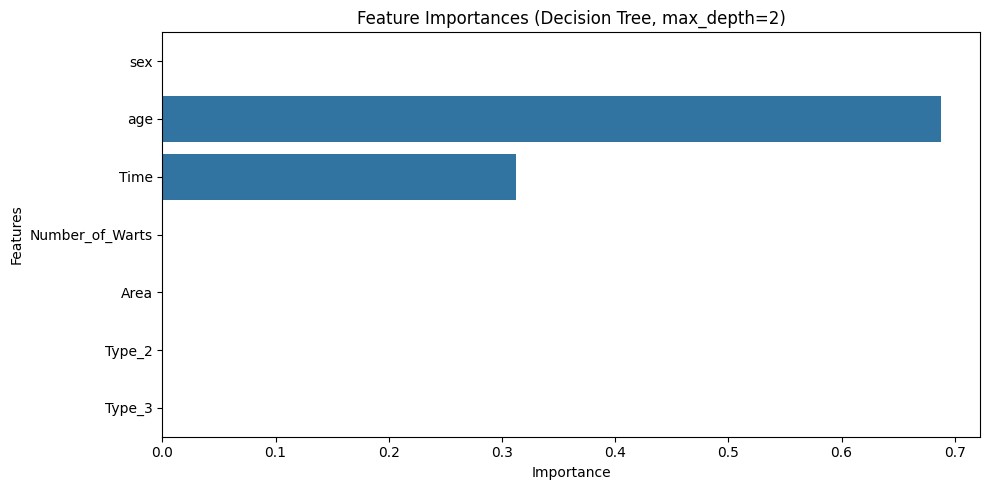

In [7]:
plt.figure(figsize=(10, 5))
feature_importances = best_dt_model.feature_importances_
sns.barplot(x=feature_importances, y=X.columns)
plt.title(f'Feature Importances (Decision Tree, max_depth={best_depth})')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

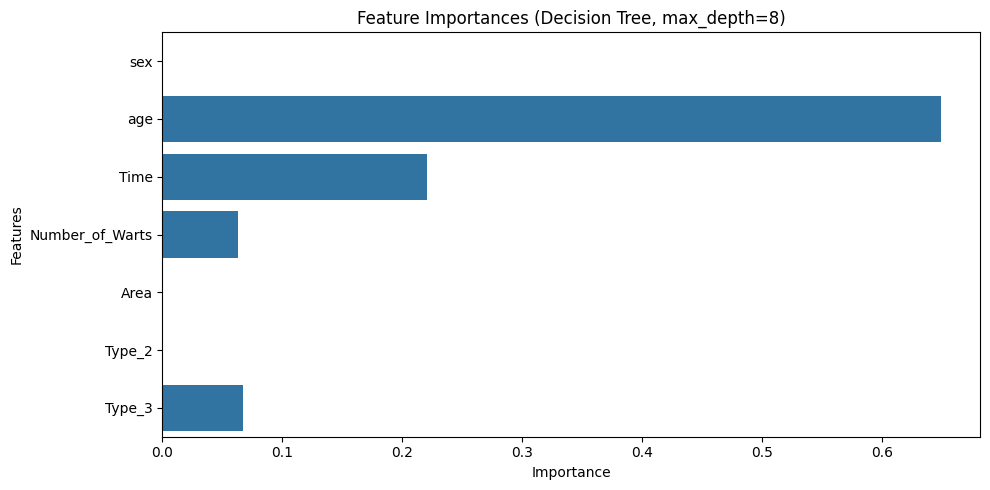

In [13]:
depth_dt = DecisionTreeClassifier(max_depth=8, random_state=42)
depth_dt.fit(X_train_scaled, y_train)
plt.figure(figsize=(10, 5))
feature_importances = depth_dt.feature_importances_
sns.barplot(x=feature_importances, y=X.columns)
plt.title(f'Feature Importances (Decision Tree, max_depth=8)')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Visualizing the Tree

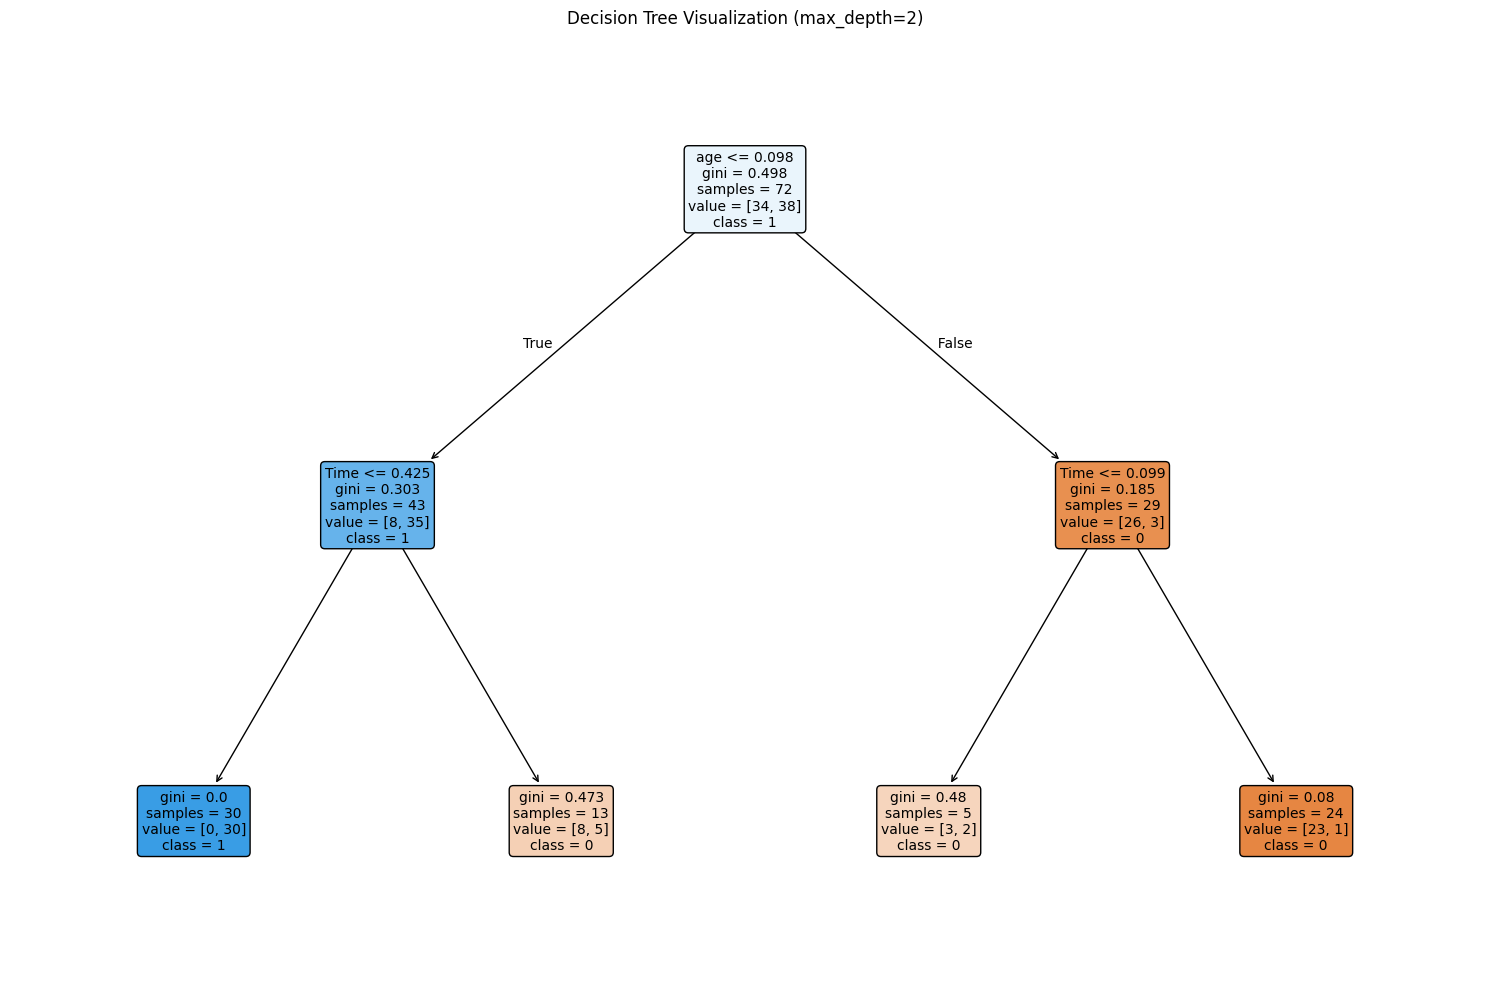

In [8]:
plt.figure(figsize=(15, 10))
plot_tree(best_dt_model, 
          feature_names=X.columns, 
          class_names=[str(c) for c in best_dt_model.classes_], 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title(f'Decision Tree Visualization (max_depth={best_depth})')
plt.tight_layout()
plt.show()

### Best `max_depth`

Based on the F1-score, **depth 2** performed best, at 83.38%.

Pushing depth to 4 caused a sharp drop — F1 fell to 65.80%. This is a textbook sign of
overfitting: at higher depths the tree starts memorizing noise in the training data and
loses its ability to generalize to the test set.

Results at depth 6, 8, and `None` (unlimited) were all identical (77.78%). This means
that once the tree reaches depth 6, it stops growing further — either the leaves are
already pure, or there's no more data left to split on at any node.


### Feature Importance

**Age** — with an importance of ~69% (0.69), this is by far the most influential feature
in the model's decisions.

**Time** — the second most important feature, at ~31% (0.31).

**All other features** (`sex`, `Number_of_Warts`, `Type`, `Area`) — importance of 0 in
this model.

That's not because they're worthless — it's a consequence of the depth limit. At
`max_depth=2`, the tree can only make at most 3 splits, and it chose to spend all of them
on its two strongest features (`age` and `Time`). The other features never got a chance
to be used.


### Reading the Tree

The tree structure shows exactly how the model classifies patients (features are
standardized, which is why the split thresholds are decimal values):

**Root node** — the first and most important decision is on `age`: `age <= 0.098`. It
covers all 72 training samples, with a Gini impurity of 0.498 (roughly an even mix of
both classes).

**Left branch (age ≤ 0.098 — True):**
Splits again on `Time <= 0.425`.
- If true: a fully pure leaf (Gini = 0.0) with 30 samples, all belonging to Class 1
  (successful treatment).
- If false: a leaf with 13 samples, most belonging to Class 0.

**Right branch (age > 0.098 — False):**
Splits on `Time <= 0.099`. Both resulting leaves are majority Class 0 (unsuccessful
treatment), but the right-hand leaf — 24 samples, Gini = 0.08 — classifies with very
high confidence.
